# Day 3 - Ensemble Learning

Breast Cancer Classification

In [1]:
import pandas as pd
import matplotlib.pyplot as mat

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, RocCurveDisplay,
    ConfusionMatrixDisplay
)

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame

print(df.shape)
df.head().round(2)

(569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.12,0.28,0.30,0.15,0.24,0.08,...,17.33,184.60,2019.0,0.16,0.67,0.71,0.27,0.46,0.12,0
1,20.57,17.77,132.90,1326.0,0.08,0.08,0.09,0.07,0.18,0.06,...,23.41,158.80,1956.0,0.12,0.19,0.24,0.19,0.28,0.09,0
2,19.69,21.25,130.00,1203.0,0.11,0.16,0.20,0.13,0.21,0.06,...,25.53,152.50,1709.0,0.14,0.42,0.45,0.24,0.36,0.09,0
3,11.42,20.38,77.58,386.1,0.14,0.28,0.24,0.11,0.26,0.10,...,26.50,98.87,567.7,0.21,0.87,0.69,0.26,0.66,0.17,0
4,20.29,14.34,135.10,1297.0,0.10,0.13,0.20,0.10,0.18,0.06,...,16.67,152.20,1575.0,0.14,0.20,0.40,0.16,0.24,0.08,0


In [3]:
X = df.drop(columns='target')
y = df['target']

# Keep the same class proportions in both sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(X_train.shape)
print(X_test.shape)

(455, 30)
(114, 30)


In [4]:
models = {
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, 'trained')

Decision Tree trained
Random Forest trained
Gradient Boosting trained


In [5]:
params = {
    'n_estimators': [10, 25, 50],
    'max_depth': [None, 3, 5],
    'min_samples_leaf': [1, 3, 5]
}

# Find the best parameter combination using cross-validation
search = GridSearchCV(
    RandomForestClassifier(random_state=42),
    params,
    cv=5,
    scoring='accuracy'
)

search.fit(X_train, y_train)

print('Best parameters:', search.best_params_)
print('CV accuracy:', round(search.best_score_, 3))

Best parameters: {'max_depth': None, 'min_samples_leaf': 3, 'n_estimators': 25}
CV accuracy: 0.956


In [6]:
best_forest = search.best_estimator_
models['Tuned Random Forest'] = best_forest

results = []

for name, model in models.items():
    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 0]

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, predictions),
        'Precision': precision_score(y_test, predictions, pos_label=0),
        'Recall': recall_score(y_test, predictions, pos_label=0),
        'F1': f1_score(y_test, predictions, pos_label=0),
        'ROC-AUC': roc_auc_score(y_test == 0, probabilities)
    })

comparison = pd.DataFrame(results)
comparison.round(3)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Decision Tree,0.912,0.848,0.929,0.886,0.916
1,Random Forest,0.956,0.951,0.929,0.940,0.994
2,Gradient Boosting,0.956,0.974,0.905,0.938,0.991
3,Tuned Random Forest,0.939,0.907,0.929,0.918,0.994


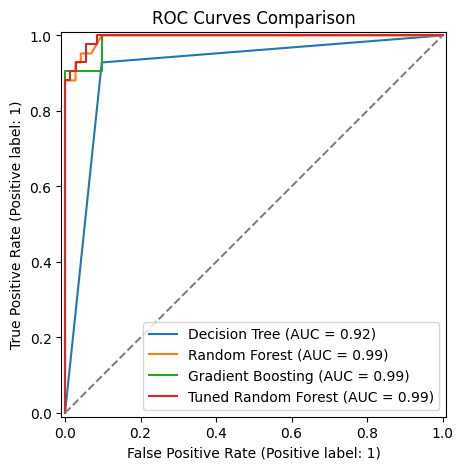

In [7]:
fig, ax = mat.subplots(figsize=(8, 5))

for name, model in models.items():
    probabilities = model.predict_proba(X_test)[:, 0]

    RocCurveDisplay.from_predictions(
        y_test == 0,
        probabilities,
        name=name,
        ax=ax
    )

ax.plot([0, 1], [0, 1], '--', color='gray')
ax.set_title('ROC Curves Comparison')

mat.show()

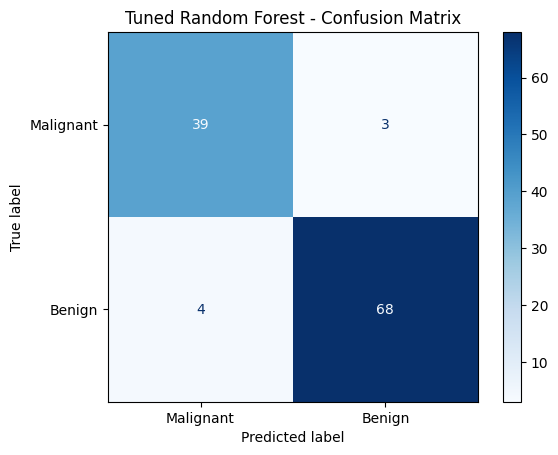

In [8]:
best_predictions = best_forest.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    best_predictions,
    labels=[0, 1],
    display_labels=['Malignant', 'Benign'],
    cmap='Blues'
)

mat.title('Tuned Random Forest - Confusion Matrix')
mat.show()

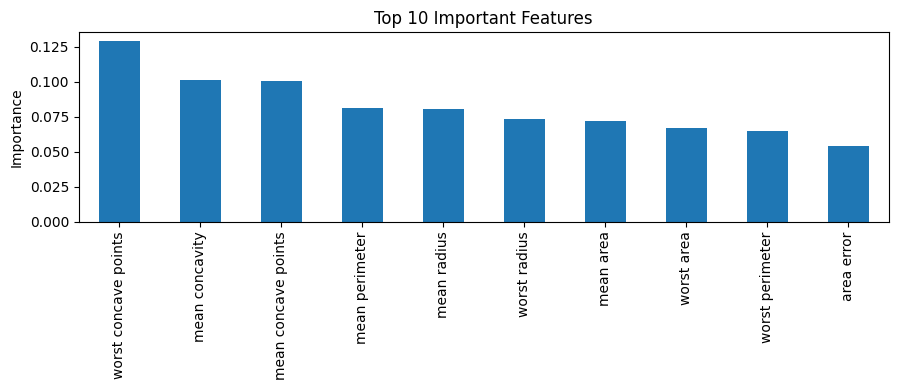

In [9]:
importance = pd.Series(
    best_forest.feature_importances_,
    index=X.columns
)

importance.sort_values(ascending=False).head(10).plot(
    kind='bar',
    figsize=(9, 4)
)

mat.title('Top 10 Important Features')
mat.ylabel('Importance')
mat.tight_layout()
mat.show()

### Conclusion

I trained three models on the Breast Cancer dataset and compared their results using the same train/test split.

Random Forest and Gradient Boosting both reached about 0.96 accuracy. Their F1 and ROC-AUC scores were also quite similar.

I also tried tuning Random Forest with GridSearchCV, but the test accuracy dropped slightly to 0.94. So in this case, the default Random Forest worked better.

The ROC curves and confusion matrix helped me see the differences between the models.